# Two research examples: inputs and targets

These short examples isolate two decisions from the research studies: constructing a temporal window and constructing a binary label. They use **explicitly constructed values**, require only NumPy and Matplotlib, and do not fit a model. Published results remain in the slides with their original attribution.

## A. A map maximum becomes a temporal input

In Nicolis, Plaza and Salas (2021), the LSTM receives 30 daily spatial maxima of an ETAS-derived intensity representation. Here we construct small arrays to make that operation visible. **These values are not fitted ETAS outputs or earthquake observations.** The six cells keep the example short; they are not the six published macrozone classes.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


### Construct 31 small daily maps

Each map has three rows and two columns. A deliberately fixed spatial pattern makes the temporal operation easy to inspect. Day numbers have no correspondence with dates in the published catalogue. The intensity scale is illustrative and uses arbitrary units.


In [2]:
activity = np.array([
    0.8, 0.7, 0.9, 1.0, 0.8, 0.6, 0.7, 1.2, 1.8, 1.4,
    1.1, 1.0, 0.9, 0.8, 1.0, 1.3, 2.2, 1.7, 1.4, 1.1,
    1.0, 0.9, 0.8, 1.1, 1.4, 1.2, 1.0, 1.5, 2.4, 1.9, 1.6
])
spatial_pattern = np.array([[0.4, 0.7], [0.6, 1.0], [0.5, 0.8]])
illustrative_maps = activity[:, None, None] * spatial_pattern[None, :, :]
day_number = np.arange(1, 32)
print("Daily maps:", illustrative_maps.shape)  # (days, rows, columns)


Daily maps: (31, 3, 2)


### Select one input window and its target

Taking the maximum over the two spatial axes produces one number per day. The first 30 numbers are the input; the following number is the target. The extra final axis in `history` identifies the single observed feature. A training batch would add an examples axis.


In [3]:
daily_max = illustrative_maps.max(axis=(1, 2))
t = 30
history = daily_max[t - 30:t, None]
target = daily_max[t]

assert illustrative_maps.shape == (31, 3, 2)
assert history.shape == (30, 1)
assert np.allclose(history[:, 0], activity[:30])
assert np.isclose(target, 1.6)

print("Input shape:", history.shape)
print("Input days:", day_number[t - 30], "to", day_number[t - 1])
print("Target day:", day_number[t], "Target value:", target)


Input shape: (30, 1)
Input days: 1 to 30
Target day: 31 Target value: 1.6


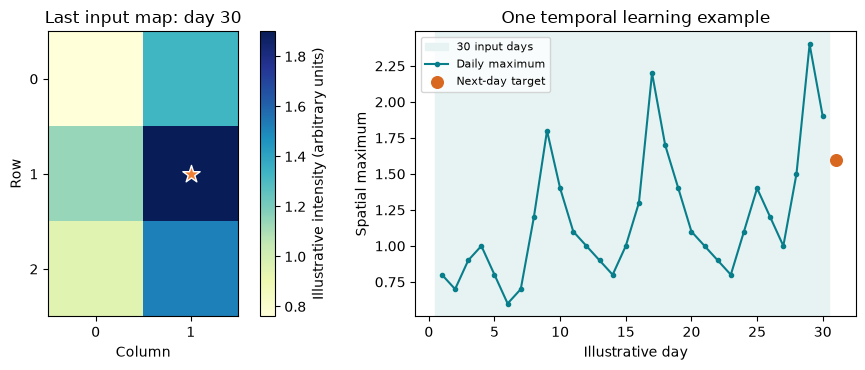

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
image = axes[0].imshow(illustrative_maps[t - 1], cmap="YlGnBu")
row, column = np.unravel_index(illustrative_maps[t - 1].argmax(), (3, 2))
axes[0].scatter(column, row, marker="*", s=170, color="#ef7f32", edgecolor="white")
axes[0].set(title="Last input map: day 30", xlabel="Column", ylabel="Row")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1, 2])
fig.colorbar(image, ax=axes[0], label="Illustrative intensity (arbitrary units)")
axes[1].axvspan(0.5, 30.5, color="#e6f3f2", label="30 input days")
axes[1].plot(day_number[:t], history[:, 0], ".-", color="#087e8b", label="Daily maximum")
axes[1].scatter(day_number[t], target, color="#d86720", s=70, label="Next-day target", zorder=3)
axes[1].set(xlabel="Illustrative day", ylabel="Spatial maximum", title="One temporal learning example")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


**Read the example:** each input number summarizes a whole map. Reducing to a maximum discards its location and the remaining spatial pattern. The published CNN branch retains maps to classify the macrozone of the next maximum. This illustration demonstrates array construction only; it reproduces neither the ETAS fit nor the published evaluation.

## B. A sequence becomes a magnitude-threshold label

The submitted manuscript derives classifier targets from **observed aftershock outcomes within 100 km and 14 days of a mainshock**. The predictors describe the mainshock. Generated GAN samples are not the source of the classifier labels.

The following constructed reference sequence illustrates that observed-outcome representation. It has 224 intervals of 90 minutes (14 days), with 2.5 marking absence and a maximum magnitude in an occupied interval. Its values are the same teaching illustration used in the slides; they are not an observed catalogue sequence or a fitted generator output.


In [5]:
sequence = np.full(224, 2.5)
occupied_bins = [12, 34, 61, 87, 108, 146, 190, 219]
sequence[occupied_bins] = [4.1, 3.4, 5.1, 4.2, 3.1, 4.6, 3.8, 4.0]

threshold = 5.0  # Change to 6.0 to ask a different question.
qualifying_bins = sequence >= threshold
label = int(qualifying_bins.any())
assert sequence.shape == (224,)
assert [int((sequence >= value).any()) for value in [5.0, 6.0]] == [1, 0]
print("Maximum magnitude:", sequence.max())
print("At least one interval with M >=", threshold, ":", label)


Maximum magnitude: 5.1
At least one interval with M >= 5.0 : 1


Threshold 5.0: label 1
Threshold 6.0: label 0


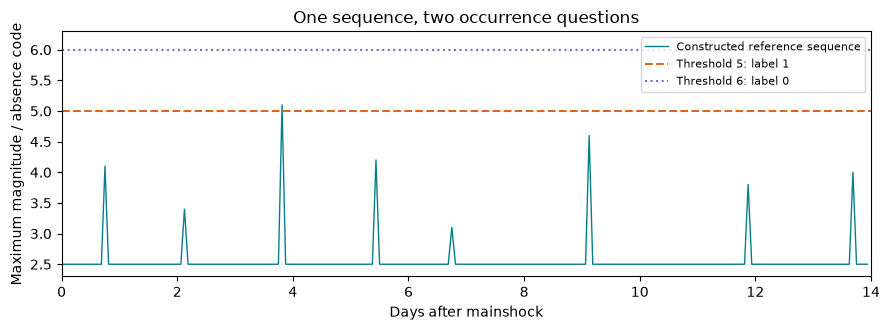

In [6]:
for threshold in [5.0, 6.0]:
    label = int((sequence >= threshold).any())
    print(f"Threshold {threshold:.1f}: label {label}")

days_after_mainshock = np.arange(224) * 90 / (24 * 60)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(days_after_mainshock, sequence, color="#087e8b", linewidth=1, label="Constructed reference sequence")
ax.axhline(5, color="#d86720", linestyle="--", label="Threshold 5: label 1")
ax.axhline(6, color="#756cc7", linestyle=":", label="Threshold 6: label 0")
ax.set(xlabel="Days after mainshock", ylabel="Maximum magnitude / absence code",
       xlim=(0, 14), ylim=(2.3, 6.3), title="One sequence, two occurrence questions")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()


**Read the example:** changing the threshold changes the scientific target. The binary label retains whether a qualifying interval exists and discards its timing, multiplicity and most of the trajectory. A supervised classifier needs many real mainshock-feature/observed-label pairs and a declared evaluation protocol.

This illustration follows the manuscript's written non-strict threshold definition. Some inherited classification scripts use a strict comparison instead. The illustrative maximum 5.1 gives the same two labels with either operator, but does not resolve that implementation discrepancy or reproduce its empirical labels. The separate occupancy comparison in the slides has its own verified threshold definition.

## Connect the examples to the practical

The temporal practical combines a **30-day input window** with a **binary future-occurrence label**. Its three catalogue channels, seven-day horizon and regional target are its own teaching task. The two examples above explain the decisions separately; they do not transfer results between the studies.

Continue with the [core LSTM tutorial](https://franplaza.github.io/courses/statsei14/tutorials/temporal.html), or consult the [references](https://franplaza.github.io/courses/statsei14/references.html) and [environment notes](https://franplaza.github.io/courses/statsei14/environment.html).
